# Cancer Gene Expression Analysis (practice data)

**FYP group:** Hira Afzal (SP23-BSI-020), Hamna Nasim (SP23-BSI-017), Namra Munir Khokhar (SP23-BSI-040)  
COMSATS University Islamabad, Department of Biosciences, BS Bioinformatics

This notebook is the Python part of our project (Galaxy practice was done first). It uses **simulated practice data** (30 cancer and 30 healthy samples, 10 genes including apoptosis genes), **not real patients**. Real GEO/TCGA data will replace it later.

**Parts**
1. Differentially expressed genes (DEGs) and volcano plot
2. Heatmap of DEGs
3. Apoptosis genes: cancer vs healthy
4. Machine learning model: predict cancer or healthy

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests

np.random.seed(42)

genes = ["TP53", "BAX", "BCL2", "CASP3", "MYC", "EGFR", "GAPDH", "ACTB", "VEGFA", "CDKN1A"]
base = [200, 150, 120, 100, 80, 90, 1000, 1200, 60, 70]
cancer_factor = [0.8, 0.4, 3.0, 0.4, 4.0, 2.5, 1.0, 1.0, 1.0, 1.0]   # how each gene changes in cancer
n = 30

rows = []
for label in ["cancer"] * n + ["healthy"] * n:
    factors = cancer_factor if label == "cancer" else [1] * len(genes)
    rows.append([np.random.poisson(b * f) for b, f in zip(base, factors)] + [label])

ids = [f"C{i+1}" for i in range(n)] + [f"H{i+1}" for i in range(n)]
data = pd.DataFrame(rows, columns=genes + ["label"], index=ids)

print(data["label"].value_counts())
data.head()

label
cancer     30
healthy    30
Name: count, dtype: int64


,TP53,BAX,BCL2,CASP3,MYC,EGFR,GAPDH,ACTB,VEGFA,CDKN1A,label
C1,155,65,338,42,340,209,982,1193,62,65,cancer
C2,158,52,365,42,310,233,957,1175,56,71,cancer
C3,185,62,329,25,314,241,979,1157,67,75,cancer
C4,171,57,384,37,310,235,1045,1153,66,77,cancer
C5,161,56,390,38,305,215,1059,1213,68,82,cancer


## Part 1: DEGs and volcano plot

        log2FC  p_value    padj    DEG
TP53   -0.3151   0.0000  0.0000  False
BAX    -1.3568   0.0000  0.0000   True
BCL2    1.5570   0.0000  0.0000   True
CASP3  -1.2925   0.0000  0.0000   True
MYC     1.9681   0.0000  0.0000   True
EGFR    1.3001   0.0000  0.0000   True
ACTB   -0.0113   0.3425  0.4352  False
CDKN1A  0.0408   0.3481  0.4352  False
GAPDH   0.0099   0.4633  0.4633  False
VEGFA   0.0369   0.4432  0.4633  False


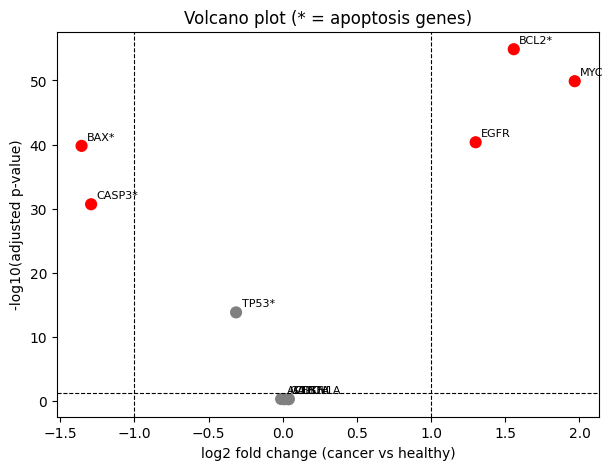

In [2]:
counts = data[genes].T                       # rows = genes, columns = samples
log_counts = np.log2(counts + 1)
cancer = log_counts.loc[:, data["label"] == "cancer"]
healthy = log_counts.loc[:, data["label"] == "healthy"]

result = pd.DataFrame(index=genes)
result["log2FC"] = cancer.mean(axis=1) - healthy.mean(axis=1)
result["p_value"] = stats.ttest_ind(cancer, healthy, axis=1).pvalue
result["padj"] = multipletests(result["p_value"], method="fdr_bh")[1]
result["DEG"] = (result["padj"] < 0.05) & (result["log2FC"].abs() > 1)
print(result.round(4).sort_values("padj"))

apoptosis = ["TP53", "BAX", "BCL2", "CASP3"]
result["-log10(padj)"] = -np.log10(result["padj"] + 1e-300)
plt.figure(figsize=(7, 5))
plt.scatter(result["log2FC"], result["-log10(padj)"], c=result["DEG"].map({True: "red", False: "grey"}), s=60)
for g in result.index:
    plt.annotate(g + ("*" if g in apoptosis else ""), (result.loc[g, "log2FC"], result.loc[g, "-log10(padj)"]),
                 fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.axvline(1, ls="--", c="black", lw=0.8); plt.axvline(-1, ls="--", c="black", lw=0.8)
plt.axhline(-np.log10(0.05), ls="--", c="black", lw=0.8)
plt.xlabel("log2 fold change (cancer vs healthy)"); plt.ylabel("-log10(adjusted p-value)")
plt.title("Volcano plot (* = apoptosis genes)")
plt.show()

**Reading it:** `log2FC` > 0 means higher in cancer. `padj` < 0.05 means the difference is unlikely to be chance. Red points are DEGs.

## Part 2: Heatmap of DEGs

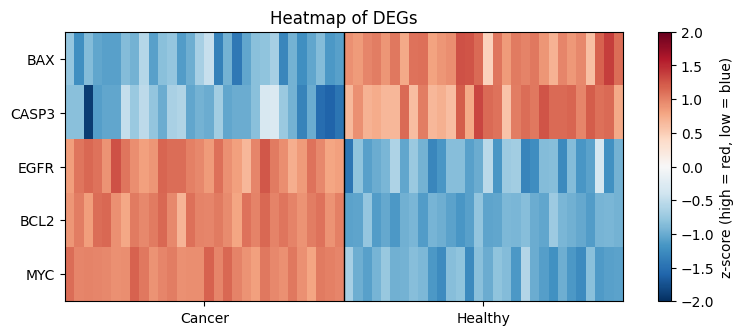

In [3]:
deg_genes = result[result["DEG"]].sort_values("log2FC").index
order = list(data.index[data["label"] == "cancer"]) + list(data.index[data["label"] == "healthy"])
heat = log_counts.loc[deg_genes, order]
heat_z = heat.sub(heat.mean(axis=1), axis=0).div(heat.std(axis=1), axis=0)

plt.figure(figsize=(9, 3.5))
plt.imshow(heat_z, cmap="RdBu_r", aspect="auto", vmin=-2, vmax=2)
plt.colorbar(label="z-score (high = red, low = blue)")
plt.yticks(range(len(heat_z.index)), heat_z.index)
plt.xticks([n/2 - 0.5, n + n/2 - 0.5], ["Cancer", "Healthy"])
plt.axvline(n - 0.5, color="black", lw=1)
plt.title("Heatmap of DEGs")
plt.show()

Each column is a patient, each row is a gene. Red = higher than average, blue = lower.

## Part 3: Apoptosis genes, cancer vs healthy

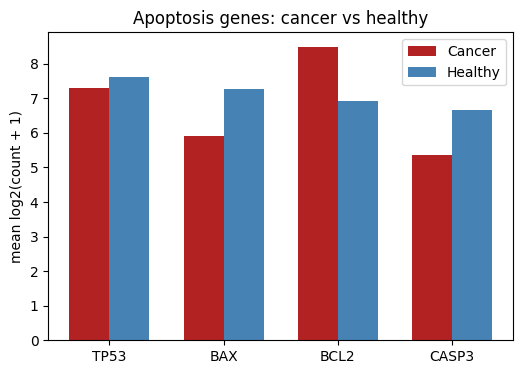

In [4]:
mean_c = cancer.loc[apoptosis].mean(axis=1)
mean_h = healthy.loc[apoptosis].mean(axis=1)
x = np.arange(len(apoptosis)); w = 0.35
plt.figure(figsize=(6, 4))
plt.bar(x - w/2, mean_c, w, label="Cancer", color="firebrick")
plt.bar(x + w/2, mean_h, w, label="Healthy", color="steelblue")
plt.xticks(x, apoptosis)
plt.ylabel("mean log2(count + 1)")
plt.title("Apoptosis genes: cancer vs healthy")
plt.legend()
plt.show()

**Meaning:** BCL2 (stops apoptosis) is higher in cancer, while BAX and CASP3 (cause apoptosis) are lower. This is the pattern expected when cancer cells escape cell death. This is simulated data, so it only shows that the code works.

## Part 4: Machine learning model (cancer or healthy)

To avoid **data leakage**, we split the samples first (80% training, 20% test) and choose DEGs using the **training samples only**. The test samples are used only at the end to check the model.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report

X = np.log2(data[genes] + 1)
y = (data["label"] == "cancer").astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# choose DEGs using the training set only
tr_c = X_train[y_train == 1]; tr_h = X_train[y_train == 0]
fc = tr_c.mean() - tr_h.mean()
pv = stats.ttest_ind(tr_c, tr_h).pvalue
padj = multipletests(pv, method="fdr_bh")[1]
selected = [g for g, f, p in zip(genes, fc, padj) if p < 0.05 and abs(f) > 1]
print("Genes used by the model:", selected)

model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train[selected], y_train)

pred = model.predict(X_test[selected])
prob = model.predict_proba(X_test[selected])[:, 1]
print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("ROC-AUC :", round(roc_auc_score(y_test, prob), 3))
print(classification_report(y_test, pred, target_names=["healthy", "cancer"]))

Genes used by the model: ['BAX', 'BCL2', 'CASP3', 'MYC', 'EGFR']
Accuracy: 1.0
ROC-AUC : 1.0
              precision    recall  f1-score   support

     healthy       1.00      1.00      1.00         6
      cancer       1.00      1.00      1.00         6

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12



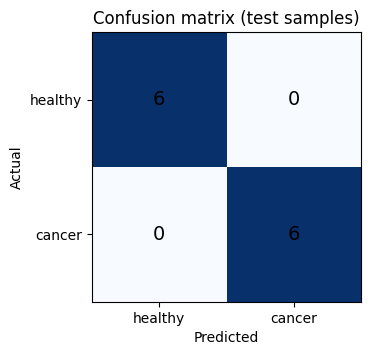

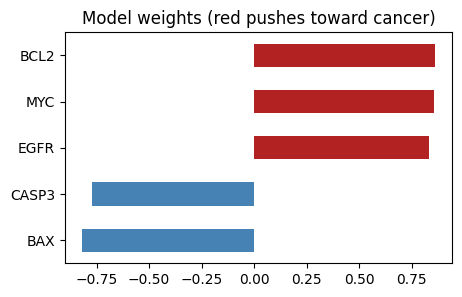

In [6]:
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(4, 3.5))
plt.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
plt.xticks([0, 1], ["healthy", "cancer"]); plt.yticks([0, 1], ["healthy", "cancer"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (test samples)")
plt.show()

coef = pd.Series(model[-1].coef_[0], index=selected).sort_values()
coef.plot(kind="barh", color=["steelblue" if v < 0 else "firebrick" for v in coef], figsize=(5, 3))
plt.title("Model weights (red pushes toward cancer)")
plt.show()

**Important:** the accuracy is very high because the simulated cancer and healthy samples are made to be very different. Real data is much harder, so real accuracy will be lower. The same code will be used on a real dataset.

## Next steps
- Replace simulated data with a real count table (GEO or TCGA)
- Add cross-validation and compare more models (Random Forest, SVM)
- Connect the trained model to the Streamlit app (`app.py`)